# LAB 2 — Collaborative Filtering บน MovieLens-100K ด้วย Surprise: เปรียบเทียบหลายเทคนิค + Offline Protocols + GUI

ขยายจาก LAB 1 (MovieMini-12) ไปสู่ **Open Dataset จริง: MovieLens-100K** (ผู้ใช้ 943 คน ภาพยนตร์ 1,682 เรื่อง คะแนน 100,000 ค่า)
โดยเรียกใช้ Library **Surprise** ซึ่งรวมอัลกอริทึมการกรองร่วมตามบทที่ 5 ไว้ครบ

| Part | เนื้อหา | หัวข้อในบทที่ 5 |
|---|---|---|
| 0 | Environment + โหลด MovieLens-100K (ratings, movies, users) | 5.2 |
| 1 | สำรวจข้อมูล: ความหนาแน่น หางยาว กิจกรรมผู้ใช้ เวลา | 5.2.2, 5.15.2 |
| 2 | Core Functions: Model wrapper + Metric (Accuracy/Ranking/Beyond-Accuracy) | 5.14, บทที่ 2 |
| 3 | การเลือกกลุ่มตัวอย่างเพื่อทำ Offline Training/Testing (6 แบบ) | 5.14, 5.16 |
| 4 | อัลกอริทึมที่เปรียบเทียบ (Surprise 12 ตัว + Popularity + EASE) | 5.4–5.12 |
| 5 | การทดลองที่ 1 — Rating: RMSE/MAE/FCP บนหลาย Split + 5-Fold CV | 5.14.1 |
| 6 | การทดลองที่ 2 — Ranking: P/R/F1/HR/MRR/MAP/nDCG/AUC (Full Catalog vs Sampled) | 5.14.2 |
| 7 | การทดลองที่ 3 — Beyond-Accuracy: Coverage, Gini, ILD, Novelty, Calibration, Personalization, ARP | บทที่ 2 |
| 8 | การทดลองที่ 4 — ผลของ Protocol: Random vs Temporal vs LOO, Full vs Sampled | 5.17.2 |
| 9 | ตัวอย่าง Output บน Validation Dataset: เทียบ Rating และ Ranking ทุกอัลกอริทึม | 5.14 |
| 10 | ตารางสรุป + Chart + Paired Bootstrap | 5.14 |
| 11 | GUI (Gradio): ข้อมูลผู้ใช้ + รายการแนะนำ + เทียบอัลกอริทึม + ทำนายคะแนน | 5.16 |

> เวลารันโดยประมาณบน Colab (CPU): 8–12 นาที ปรับ `N_EVAL_USERS` ใน Part 2 เพื่อลด/เพิ่มเวลา
>
> ถ้า `from surprise import ...` แจ้ง error เกี่ยวกับ numpy (binary incompatibility) ให้รัน
> `!pip install -q --no-cache-dir --force-reinstall scikit-surprise` แล้วเลือก Runtime → Restart session ก่อนรันใหม่

In [1]:
# ============================================================
# Part 0 — Environment & Dataset
# ============================================================
!pip -q install scikit-surprise gradio

import math, random, warnings, itertools, time, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score

from surprise import (Dataset, Reader, accuracy, NormalPredictor, BaselineOnly, KNNBasic, KNNWithMeans,
                      KNNWithZScore, KNNBaseline, SVD, SVDpp, NMF, SlopeOne, CoClustering)
from surprise.model_selection import train_test_split, cross_validate

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
SEED = 42
np.random.seed(SEED); random.seed(SEED)

GENRES = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary", "Drama",
          "Fantasy", "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]

def load_movielens_100k():
    """โหลด MovieLens-100K ผ่าน Surprise (ดาวน์โหลดจาก GroupLens ครั้งแรก)
    แล้วอ่าน u.item (ชื่อ/ปี/แนว) และ u.user (อายุ/เพศ/อาชีพ) จากโฟลเดอร์เดียวกัน
    ถ้าดาวน์โหลดไม่ได้ จะใช้สำเนาจาก GitHub (RecBole) เป็นทางสำรอง"""
    base = Path.home() / ".surprise_data" / "ml-100k" / "ml-100k"
    try:
        Dataset.load_builtin("ml-100k", prompt=False)
    except Exception as e:
        print("load_builtin ไม่สำเร็จ:", type(e).__name__)
    if (base / "u.data").exists():
        ratings = pd.read_csv(base / "u.data", sep="\t", names=["user_id", "item_id", "rating", "timestamp"])
        it = pd.read_csv(base / "u.item", sep="|", header=None, encoding="latin-1")
        items = pd.DataFrame({"item_id": it[0], "title": it[1]})
        flags = it.iloc[:, 5:24].values
        items["genre"] = ["|".join(g for g, f in zip(GENRES, row) if f == 1) or "unknown" for row in flags]
        users = pd.read_csv(base / "u.user", sep="|", names=["user_id", "age", "gender", "occupation", "zip"])
        src = str(base)
    else:
        url = "https://raw.githubusercontent.com/RUCAIBox/RecBole/master/dataset/ml-100k/"
        ratings = pd.read_csv(url + "ml-100k.inter", sep="\t"); ratings.columns = ["user_id", "item_id", "rating", "timestamp"]
        it = pd.read_csv(url + "ml-100k.item", sep="\t", dtype=str); it.columns = ["item_id", "title", "year", "genre"]
        it["title"] = it["title"] + " (" + it["year"].fillna("") + ")"
        items = it[["item_id", "title"]].assign(genre=it["genre"].fillna("unknown").str.replace(" ", "|"))
        users = pd.read_csv(url + "ml-100k.user", sep="\t"); users.columns = ["user_id", "age", "gender", "occupation", "zip"]
        src = url
    for df in (ratings, items, users):
        for c in ("user_id", "item_id"):
            if c in df.columns: df[c] = df[c].astype(str)
    ratings["rating"] = ratings["rating"].astype(float)
    items["year"] = items["title"].str.extract(r"\((\d{4})\)\s*$")[0]
    return ratings, items, users, src

ratings, items, users, DATA_SRC = load_movielens_100k()
TITLE = dict(zip(items.item_id, items.title)); GENRE = dict(zip(items.item_id, items.genre))
YEAR = dict(zip(items.item_id, items.year))
READER = Reader(rating_scale=(1, 5))
LIKE_T = 4.0                                   # rating >= 4 = "ชอบ" (relevant) เหมือน LAB 1

print("Source:", DATA_SRC)
print(f"Users={ratings.user_id.nunique()}  Items={ratings.item_id.nunique()}  Ratings={len(ratings)}")
display(ratings.head()); display(items.head()); display(users.head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 26.9 MB/s eta 0:00:00
Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Source: /root/.surprise_data/ml-100k/ml-100k
Users=943  Items=1682  Ratings=100000


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


,item_id,title,genre,year
0,1,Toy Story (1995),Animation|Children's|Comedy,1995
1,2,GoldenEye (1995),Action|Adventure|Thriller,1995
2,3,Four Rooms (1995),Thriller,1995
3,4,Get Shorty (1995),Action|Comedy|Drama,1995
4,5,Copycat (1995),Crime|Drama|Thriller,1995


,user_id,age,gender,occupation,zip
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


## Part 1 — สำรวจข้อมูล (หัวข้อ 5.2.2 และ 5.15.2)
ตัวเลขที่ต้องดูก่อนสร้างแบบจำลอง: ความหนาแน่น การกระจายคะแนน จำนวนคะแนนต่อผู้ใช้/ต่อรายการ (หางยาว) และช่วงเวลา

,value
density,0.063047
global mean,3.52986
ratings/user (median),65.0
ratings/user (min),20
ratings/item (median),27.0
items with < 5 ratings,333
share of liked (>=4),0.55375
top 10% items share of ratings,0.42702
first date,1997-09-20
last date,1998-04-22


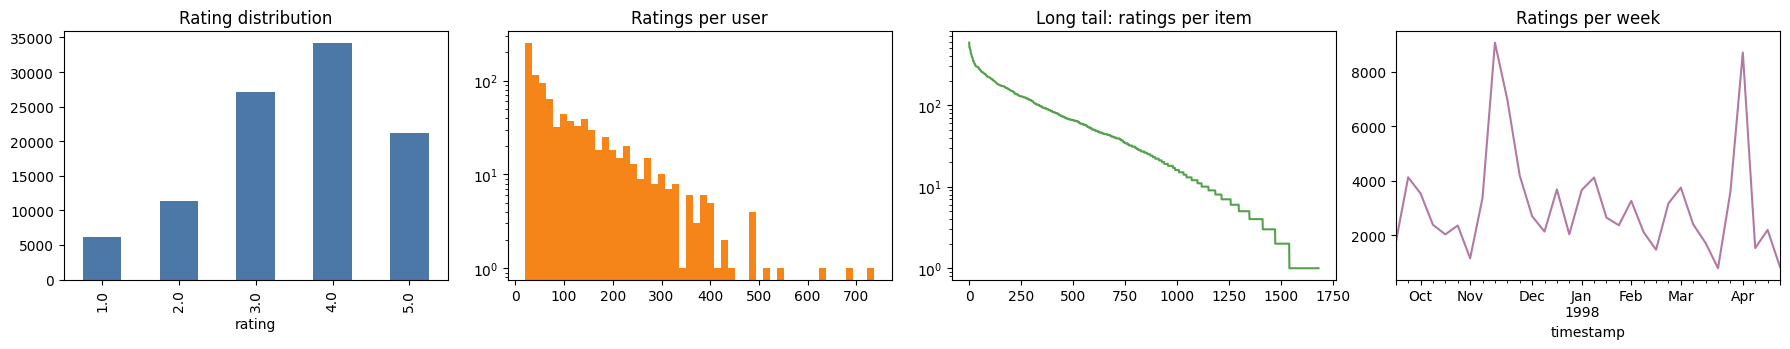

In [2]:
n_u, n_i = ratings.user_id.nunique(), ratings.item_id.nunique()
per_user = ratings.groupby("user_id").size(); per_item = ratings.groupby("item_id").size()
ts = pd.to_datetime(ratings.timestamp, unit="s")
eda = pd.Series({
    "density": len(ratings) / (n_u * n_i),
    "global mean": ratings.rating.mean(),
    "ratings/user (median)": per_user.median(), "ratings/user (min)": per_user.min(),
    "ratings/item (median)": per_item.median(), "items with < 5 ratings": int((per_item < 5).sum()),
    "share of liked (>=4)": (ratings.rating >= LIKE_T).mean(),
    "top 10% items share of ratings": per_item.sort_values(ascending=False).head(int(0.1 * n_i)).sum() / len(ratings),
    "first date": ts.min().date(), "last date": ts.max().date()})
display(eda.to_frame("value"))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C78A8"); ax[0].set_title("Rating distribution")
ax[1].hist(per_user, bins=50, color="#F58518"); ax[1].set_yscale("log"); ax[1].set_title("Ratings per user")
ax[2].plot(np.sort(per_item.values)[::-1], color="#54A24B"); ax[2].set_yscale("log"); ax[2].set_title("Long tail: ratings per item")
ts.dt.to_period("W").value_counts().sort_index().plot(ax=ax[3], color="#B279A2"); ax[3].set_title("Ratings per week")
plt.tight_layout(); plt.show()
# สังเกต: ความหนาแน่นราว 6% (MovieMini-12 = 33%) แต่ผู้ใช้แต่ละคนมีอย่างน้อย 20 คะแนน → kNN มีหลักฐานมากกว่า LAB 1 มาก

## Part 2 — Core Functions
- **Model wrapper**: ห่ออัลกอริทึมของ Surprise และโมเดลที่เขียนเอง (Popularity, EASE) ให้มี interface เดียวกัน
  `fit(trainset)` → `predict(user, item)` (คะแนน 1–5) และ `scores(inner_uid)` (คะแนนจัดอันดับทุกรายการ)
- **Metric**: Rating (RMSE, MAE, FCP), Ranking (P/R/F1/HR/MRR/MAP/nDCG@K, AUC) และ Beyond-Accuracy

In [3]:
# ============================================================
# Core Functions — Model wrapper + Metrics + Evaluation engine
# ============================================================
K = 10                     # Top-K สำหรับ ranking
N_EVAL_USERS = 300         # จำนวนผู้ใช้ที่สุ่มมาประเมิน ranking (ทั้งหมด = None) — ลดเพื่อให้รันเร็วขึ้น
N_NEG = 100                # Sampled Negatives: สุ่มรายการลบ 100 รายการต่อผู้ใช้

def df_to_trainset(df):
    return Dataset.load_from_df(df[["user_id", "item_id", "rating"]], READER).build_full_trainset()

def df_to_testset(df):
    return list(df[["user_id", "item_id", "rating"]].itertuples(index=False, name=None))

class SurpriseModel:
    """ห่ออัลกอริทึมของ Surprise ให้มี scores(inner_u) สำหรับจัดอันดับทุกรายการ"""
    rating_model = True
    def __init__(self, name, factory, family):
        self.name, self.factory, self.family = name, factory, family
    def fit(self, trainset):
        self.ts = trainset; self.algo = self.factory(); self.algo.fit(trainset); return self
    def predict(self, uid, iid):
        return float(self.algo.predict(str(uid), str(iid)).est)
    def scores(self, u):
        a, ts = self.algo, self.ts; mu = ts.global_mean
        if isinstance(a, SVDpp):                                   # vectorized: mu+bu+bi+qi·(pu+|N(u)|^-1/2 Σ yj)
            Iu = [j for j, _ in ts.ur[u]]
            imp = a.yj[Iu].sum(0) / np.sqrt(len(Iu)) if Iu else 0
            return mu + a.bu[u] + a.bi + a.qi @ (a.pu[u] + imp)
        if isinstance(a, SVD):
            return (mu + a.bu[u] + a.bi if a.biased else 0) + a.qi @ a.pu[u]
        if isinstance(a, NMF):
            return (mu + a.bu[u] + a.bi if a.biased else 0) + a.qi @ a.pu[u]
        if isinstance(a, BaselineOnly):
            return mu + a.bu[u] + a.bi
        out = np.empty(ts.n_items)                                 # generic: เรียก estimate ทีละรายการ
        for i in range(ts.n_items):
            try:
                est = a.estimate(u, i)
                out[i] = est[0] if isinstance(est, tuple) else est
            except Exception:                                      # PredictionImpossible → ค่าเฉลี่ยรวม
                out[i] = mu
        return out

class PopularityModel:
    """จำนวนผู้ชอบ (rating>=4) ในข้อมูลฝึก — ranking อย่างเดียว"""
    rating_model, family = False, "Baseline"
    def __init__(self, name="Popularity"): self.name = name
    def fit(self, ts):
        self.ts = ts; self.pop = np.zeros(ts.n_items)
        for _, i, r in ts.all_ratings():
            if r >= LIKE_T: self.pop[i] += 1
        return self
    def predict(self, uid, iid): return np.nan
    def scores(self, u): return self.pop.copy()

class EASEModel:
    """EASE (Steck 2019) บนเมทริกซ์ชอบ 0/1: B = -P/diag(P), diag(B)=0"""
    rating_model, family = False, "Implicit"
    def __init__(self, lam=500.0, name="EASE"): self.lam, self.name = lam, name
    def fit(self, ts):
        self.ts = ts; X = np.zeros((ts.n_users, ts.n_items), dtype=np.float32)
        for u, i, r in ts.all_ratings():
            if r >= LIKE_T: X[u, i] = 1
        P = np.linalg.inv(X.T @ X + self.lam * np.eye(ts.n_items))
        B = -P / np.diag(P); np.fill_diagonal(B, 0); self.X, self.B = X, B
        return self
    def predict(self, uid, iid): return np.nan
    def scores(self, u): return self.X[u] @ self.B

# ---------- Metrics (ชุดเดียวกับ LAB 1 และต้นแบบบทที่ 3) ----------
def precision_at_k(recs, rel, k): return len(set(recs[:k]) & set(rel)) / k if k else 0.0
def recall_at_k(recs, rel, k): rel = set(rel); return len(set(recs[:k]) & rel) / len(rel) if rel else 0.0
def f1_at_k(recs, rel, k):
    p, r = precision_at_k(recs, rel, k), recall_at_k(recs, rel, k); return 0.0 if p + r == 0 else 2*p*r/(p+r)
def hr_at_k(recs, rel, k): return float(bool(set(recs[:k]) & set(rel)))
def reciprocal_rank(recs, rel):
    rel = set(rel)
    for rank, iid in enumerate(recs, 1):
        if iid in rel: return 1.0 / rank
    return 0.0
def ap_at_k(recs, rel, k):
    rel = set(rel); hits = 0; s = 0.0
    for n, iid in enumerate(recs[:k], 1):
        if iid in rel: hits += 1; s += hits / n
    return s / min(len(rel), k) if rel else 0.0
def ndcg_at_k(recs, rel, k):
    rel = set(rel)
    dcg = sum(1/math.log2(n+2) for n, iid in enumerate(recs[:k]) if iid in rel)
    idcg = sum(1/math.log2(n+2) for n in range(min(len(rel), k)))
    return dcg / idcg if idcg else 0.0

def rating_metrics(preds):
    """preds = ผลจาก algo.test(): RMSE, MAE, FCP และสัดส่วนที่ทำนายไม่ได้ (cold start)"""
    impossible = np.mean([p.details.get("was_impossible", False) for p in preds])
    return {"RMSE": accuracy.rmse(preds, verbose=False), "MAE": accuracy.mae(preds, verbose=False),
            "FCP": accuracy.fcp(preds, verbose=False), "Impossible%": 100 * impossible}

# ---------- Beyond-Accuracy ----------
G_INDEX = {g: k for k, g in enumerate(GENRES)}
def genre_vec(iid):
    v = np.zeros(len(GENRES))
    for g in GENRE.get(iid, "unknown").split("|"): v[G_INDEX.get(g, 0)] = 1
    return v
GVEC = {iid: genre_vec(iid) for iid in items.item_id}

def coverage(all_recs, n_catalog): return len(set(all_recs)) / n_catalog
def gini_coefficient(all_recs, catalog):
    counts = pd.Series(all_recs).value_counts()
    x = np.sort(np.array([counts.get(i, 0) for i in catalog], dtype=float)); n = len(x)
    return float((2*np.sum(np.arange(1, n+1)*x)/(n*x.sum())) - (n+1)/n) if x.sum() else 0.0
def ild(rec_ids):
    if len(rec_ids) < 2: return 0.0
    V = np.array([GVEC[i] for i in rec_ids]); V = V / np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-12)
    D = 1 - V @ V.T; return float(D[np.triu_indices(len(rec_ids), 1)].mean())
def novelty(rec_ids, pop, n_users):
    return float(np.mean([-math.log2(max(1, pop.get(i, 1)) / n_users) for i in rec_ids])) if rec_ids else 0.0
def calibration_genre(hist_ids, rec_ids):
    hp = sum(GVEC[i] for i in hist_ids); rp = sum(GVEC[i] for i in rec_ids)
    if np.sum(hp) == 0 or np.sum(rp) == 0: return np.nan
    return float(1 - 0.5*np.abs(hp/hp.sum() - rp/rp.sum()).sum())
def personalization(lists, max_pairs=20000, seed=SEED):
    L = [set(x) for x in lists]; pairs = list(itertools.combinations(range(len(L)), 2))
    if not pairs: return np.nan
    if len(pairs) > max_pairs: pairs = random.Random(seed).sample(pairs, max_pairs)
    return float(1 - np.mean([len(L[a] & L[b]) / max(len(L[a]), 1) for a, b in pairs]))

# ---------- Ranking evaluation engine ----------
def eval_users(test_df, train_ts, n=N_EVAL_USERS, seed=SEED):
    """เลือกผู้ใช้ที่ประเมินได้: อยู่ในชุดฝึก และมีรายการ relevant ในชุดทดสอบ (สุ่ม n คนด้วย seed เดียวกันทุกโมเดล)"""
    rel = test_df[test_df.rating >= LIKE_T]
    cand = sorted(set(rel.user_id) & set(train_ts._raw2inner_id_users), key=int)
    if n and len(cand) > n: cand = sorted(random.Random(seed).sample(cand, n), key=int)
    return cand

def evaluate_ranking(model, train_ts, test_df, users_eval, k=K, n_neg=N_NEG, seed=SEED, keep_lists=False):
    rng = np.random.default_rng(seed)
    inner2raw = np.array([train_ts.to_raw_iid(j) for j in range(train_ts.n_items)])
    pop = {train_ts.to_raw_iid(i): len(v) for i, v in train_ts.ir.items()}
    rel_by_user = test_df[test_df.rating >= LIKE_T].groupby("user_id")["item_id"].apply(set).to_dict()
    rows, all_recs, lists = [], [], {}
    for uid in users_eval:
        u = train_ts.to_inner_uid(uid)
        seen = np.zeros(train_ts.n_items, bool); seen[[j for j, _ in train_ts.ur[u]]] = True
        cand = np.where(~seen)[0]
        rel = {r for r in rel_by_user.get(uid, set()) if r in train_ts._raw2inner_id_items}
        if not rel: continue
        sc_all = model.scores(u); sc = sc_all[cand]
        order = cand[np.argsort(-sc, kind="stable")]
        ranked = list(inner2raw[order]); topk = ranked[:k]
        y = np.isin(inner2raw[cand], list(rel)).astype(int)
        # Sampled protocol: รายการ relevant ทุกตัว + รายการลบที่สุ่ม n_neg ตัว
        neg = cand[y == 0]; neg_s = rng.choice(neg, size=min(n_neg, len(neg)), replace=False)
        pos = cand[y == 1]; sub = np.concatenate([pos, neg_s])
        sub_rank = list(inner2raw[sub[np.argsort(-sc_all[sub], kind="stable")]])
        hist_ids = [train_ts.to_raw_iid(j) for j, _ in train_ts.ur[u]]
        rows.append({"user_id": uid, "n_rel": len(rel),
            f"Precision@{k}": precision_at_k(topk, rel, k), f"Recall@{k}": recall_at_k(topk, rel, k),
            f"F1@{k}": f1_at_k(topk, rel, k), f"HR@{k}": hr_at_k(topk, rel, k),
            "MRR": reciprocal_rank(ranked, rel), f"MAP@{k}": ap_at_k(topk, rel, k), f"nDCG@{k}": ndcg_at_k(topk, rel, k),
            "AUC": roc_auc_score(y, sc) if 0 < y.sum() < len(y) else np.nan,
            f"HR@{k}(sampled)": hr_at_k(sub_rank[:k], rel, k), f"nDCG@{k}(sampled)": ndcg_at_k(sub_rank[:k], rel, k),
            "ILD": ild(topk), "Novelty": novelty(topk, pop, train_ts.n_users),
            "Calibration": calibration_genre(hist_ids, topk), "ARP": float(np.mean([pop.get(i, 0) for i in topk]))})
        all_recs += topk; lists[uid] = topk
    detail = pd.DataFrame(rows)
    summary = detail.drop(columns=["user_id"]).mean(numeric_only=True).to_dict()
    catalog = list(inner2raw)
    summary.update({"Coverage": coverage(all_recs, len(catalog)), "Gini": gini_coefficient(all_recs, catalog),
                    "Personalization": personalization(list(lists.values())), "n_users": len(detail)})
    return (pd.Series(summary), detail, lists) if keep_lists else (pd.Series(summary), detail)

print("Core functions ready. K =", K, "| N_EVAL_USERS =", N_EVAL_USERS, "| N_NEG =", N_NEG)

Core functions ready. K = 10 | N_EVAL_USERS = 300 | N_NEG = 100


## Part 3 — การเลือกกลุ่มตัวอย่างเพื่อทำ Offline Training / Testing
วิธีแบ่งข้อมูลเปลี่ยนคำถามที่การทดลองตอบ และเปลี่ยนตัวเลขได้มาก จึงต้องระบุใน Protocol Card เสมอ

| Split | วิธีสุ่ม | ตอบคำถาม | ข้อควรระวัง |
|---|---|---|---|
| S1 Random 80/20 | สุ่มระดับคะแนน (Surprise `train_test_split`) | ทำนายช่องว่างแบบสุ่ม | ใช้อนาคตทำนายอดีต (leakage ด้านเวลา) |
| S2 Per-user 80/20 | สุ่ม 20% ของทุกผู้ใช้ (stratified) | ทุกผู้ใช้มีน้ำหนักในชุดทดสอบ | ยังไม่สนใจเวลา |
| S3 Global Temporal | ตัดตามเวลา 80% แรก → train | สถานการณ์จริง: ฝึกอดีต ทดสอบอนาคต | มีผู้ใช้/รายการใหม่ (cold start) |
| S4 Per-user Temporal | 20% ล่าสุดของแต่ละผู้ใช้ → test | คาดเดาความชอบถัดไปของผู้ใช้เดิม | **ใช้เป็น Validation หลักของ Lab** |
| S5 Leave-One-Liked-Out | กันเรื่องที่ชอบ 1 เรื่องต่อผู้ใช้ | HR@K แบบเดียวกับบทที่ 3–5 | มีรายการ relevant เพียง 1 |
| S6 5-Fold CV | Surprise `cross_validate` | ความแปรปรวนของ RMSE/MAE | ใช้กับ rating เท่านั้น |

,Split,train,test,test users,cold-start users,cold-start items,test liked %,train end,test start
0,S1 Random 80/20,80000,20000,940,0,29,54.95,1998-04-22,1997-09-20
1,S2 Per-user 80/20,80000,20000,943,0,34,54.79,1998-04-22,1997-09-20
2,S3 Global Temporal,80003,19997,301,192,66,56.52,1998-03-07,1998-03-07
3,S4 Per-user Temporal,80367,19633,943,0,67,47.77,1998-04-22,1997-09-20
4,S5 Leave-One-Liked-Out,99058,942,942,0,0,100.00,1998-04-22,1997-09-20


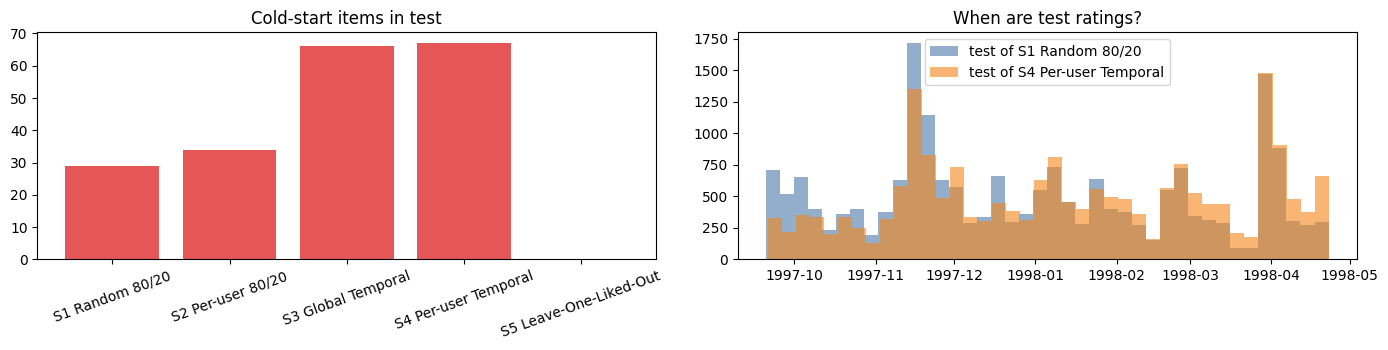

In [4]:
def split_random(df, test_size=0.2, seed=SEED):
    te = df.sample(frac=test_size, random_state=seed); return df.drop(te.index), te

def split_per_user(df, test_size=0.2, seed=SEED):
    te = df.groupby("user_id").sample(frac=test_size, random_state=seed)
    return df.drop(te.index), te

def split_global_temporal(df, train_frac=0.8):
    cut = df.timestamp.quantile(train_frac); return df[df.timestamp <= cut], df[df.timestamp > cut]

def split_user_temporal(df, test_size=0.2):
    d = df.sort_values(["user_id", "timestamp"]).copy()
    d["rk"] = d.groupby("user_id").cumcount(); d["n"] = d.groupby("user_id")["item_id"].transform("size")
    is_test = d.rk >= np.ceil(d.n * (1 - test_size))
    return df.loc[d.index[~is_test]], df.loc[d.index[is_test]]

def split_leave_one_liked_out(df, seed=SEED):
    liked = df[df.rating >= LIKE_T]
    te = liked.groupby("user_id").sample(n=1, random_state=seed)
    return df.drop(te.index), te

SPLITS = {"S1 Random 80/20": split_random(ratings), "S2 Per-user 80/20": split_per_user(ratings),
          "S3 Global Temporal": split_global_temporal(ratings), "S4 Per-user Temporal": split_user_temporal(ratings),
          "S5 Leave-One-Liked-Out": split_leave_one_liked_out(ratings)}
MAIN_SPLIT = "S4 Per-user Temporal"

split_rows = []
for name, (tr, te) in SPLITS.items():
    split_rows.append({"Split": name, "train": len(tr), "test": len(te), "test users": te.user_id.nunique(),
        "cold-start users": len(set(te.user_id) - set(tr.user_id)), "cold-start items": len(set(te.item_id) - set(tr.item_id)),
        "test liked %": 100 * (te.rating >= LIKE_T).mean(),
        "train end": pd.to_datetime(tr.timestamp.max(), unit="s").date(),
        "test start": pd.to_datetime(te.timestamp.min(), unit="s").date()})
split_table = pd.DataFrame(split_rows); display(split_table.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
ax[0].bar(split_table.Split, split_table["cold-start items"], color="#E45756"); ax[0].set_title("Cold-start items in test")
ax[0].tick_params(axis="x", rotation=20)
for name, c in [("S1 Random 80/20", "#4C78A8"), ("S4 Per-user Temporal", "#F58518")]:
    tr, te = SPLITS[name]
    ax[1].hist(pd.to_datetime(te.timestamp, unit="s"), bins=40, alpha=.6, color=c, label=f"test of {name}")
ax[1].legend(); ax[1].set_title("When are test ratings?")
plt.tight_layout(); plt.show()
# สังเกต: S3 มีผู้ใช้ใหม่จำนวนมากในชุดทดสอบ → การกรองร่วมทำนายไม่ได้ (Impossible%) = ปัญหา Cold Start (5.15.1)

## Part 4 — อัลกอริทึมที่เปรียบเทียบ
| ตระกูล (บทที่ 5) | อัลกอริทึม (Surprise class) | หัวข้อ |
|---|---|---|
| Baseline | NormalPredictor, BaselineOnly (ALS), Popularity* | 5.8 |
| Memory-based | KNNBasic (user, cosine), KNNWithMeans (user, pearson), KNNWithMeans (item, pearson), KNNWithZScore (user), KNNBaseline (item, pearson_baseline + shrinkage) | 5.4–5.6 |
| Latent factor | SVD (Funk-SVD+bias, SGD), SVD++, NMF | 5.9–5.10 |
| อื่น ๆ | SlopeOne, CoClustering | — |
| Implicit ranking | EASE* (λ=500) | 5.12.2 |

\* เขียนเองในส่วน Core Functions เพราะ Surprise ไม่มี

In [5]:
def make_models():
    sim = lambda name, ub, **kw: {"name": name, "user_based": ub, **kw}
    return [
        SurpriseModel("NormalPredictor", lambda: NormalPredictor(), "Baseline"),
        SurpriseModel("BaselineOnly", lambda: BaselineOnly(bsl_options={"method": "als", "n_epochs": 10}, verbose=False), "Baseline"),
        PopularityModel(),
        SurpriseModel("UserKNN-Basic(cos)", lambda: KNNBasic(k=40, sim_options=sim("cosine", True), verbose=False), "Memory-based"),
        SurpriseModel("UserKNN-Means(pearson)", lambda: KNNWithMeans(k=40, sim_options=sim("pearson", True), verbose=False), "Memory-based"),
        SurpriseModel("ItemKNN-Means(pearson)", lambda: KNNWithMeans(k=40, sim_options=sim("pearson", False), verbose=False), "Memory-based"),
        SurpriseModel("UserKNN-ZScore", lambda: KNNWithZScore(k=40, sim_options=sim("pearson", True), verbose=False), "Memory-based"),
        SurpriseModel("ItemKNN-Baseline", lambda: KNNBaseline(k=40, sim_options=sim("pearson_baseline", False, shrinkage=100), verbose=False), "Memory-based"),
        SurpriseModel("SVD", lambda: SVD(n_factors=100, n_epochs=20, random_state=SEED), "Latent factor"),
        SurpriseModel("SVD++", lambda: SVDpp(n_factors=20, n_epochs=20, random_state=SEED), "Latent factor"),
        SurpriseModel("NMF", lambda: NMF(n_factors=15, n_epochs=50, random_state=SEED), "Latent factor"),
        SurpriseModel("SlopeOne", lambda: SlopeOne(), "Other"),
        SurpriseModel("CoClustering", lambda: CoClustering(n_cltr_u=3, n_cltr_i=3, random_state=SEED), "Other"),
        EASEModel(lam=500.0)]

MODEL_NAMES = [m.name for m in make_models()]
RATING_MODELS = [m.name for m in make_models() if m.rating_model]
FAMILY = {m.name: m.family for m in make_models()}
def get_model(name): return [m for m in make_models() if m.name == name][0]
display(pd.DataFrame({"Model": MODEL_NAMES, "Family": [FAMILY[n] for n in MODEL_NAMES],
                      "Rating?": [n in RATING_MODELS for n in MODEL_NAMES]}))

,Model,Family,Rating?
0,NormalPredictor,Baseline,True
1,BaselineOnly,Baseline,True
2,Popularity,Baseline,False
3,UserKNN-Basic(cos),Memory-based,True
4,UserKNN-Means(pearson),Memory-based,True
5,ItemKNN-Means(pearson),Memory-based,True
6,UserKNN-ZScore,Memory-based,True
7,ItemKNN-Baseline,Memory-based,True
8,SVD,Latent factor,True
9,SVD++,Latent factor,True


## Part 5 — การทดลองที่ 1: Rating Prediction บนหลาย Split + 5-Fold CV
ฝึกบนชุดฝึกของแต่ละ Split แล้วทำนายคะแนนในชุดทดสอบ → RMSE, MAE, FCP (Fraction of Concordant Pairs), %ทำนายไม่ได้ และเวลา

In [6]:
TRAINSETS = {name: (df_to_trainset(tr), te) for name, (tr, te) in SPLITS.items()}
rating_rows, FITTED = [], {}
for split_name in ["S1 Random 80/20", "S2 Per-user 80/20", "S3 Global Temporal", "S4 Per-user Temporal"]:
    ts_, te = TRAINSETS[split_name]; testset = df_to_testset(te)
    for name in RATING_MODELS:
        t0 = time.time(); m = get_model(name).fit(ts_); fit_t = time.time() - t0
        t0 = time.time(); preds = m.algo.test(testset); test_t = time.time() - t0
        rating_rows.append({"Split": split_name, "Model": name, "Family": FAMILY[name], **rating_metrics(preds),
                            "fit_s": fit_t, "test_s": test_t})
        if split_name == MAIN_SPLIT: FITTED[name] = m
    print("done", split_name)
rating_results = pd.DataFrame(rating_rows)
display(rating_results.pivot(index="Model", columns="Split", values="RMSE").sort_values(MAIN_SPLIT).round(4))
display(rating_results[rating_results.Split == MAIN_SPLIT].sort_values("RMSE").round(4).reset_index(drop=True))

# 5-Fold Cross-Validation (S6): ค่าเฉลี่ย ± ส่วนเบี่ยงเบนมาตรฐาน
data_all = Dataset.load_from_df(ratings[["user_id", "item_id", "rating"]], READER)
cv_rows = []
for name in RATING_MODELS:
    r = cross_validate(get_model(name).factory(), data_all, measures=["RMSE", "MAE"], cv=5, verbose=False)
    cv_rows.append({"Model": name, "RMSE mean": np.mean(r["test_rmse"]), "RMSE std": np.std(r["test_rmse"]),
                    "MAE mean": np.mean(r["test_mae"]), "MAE std": np.std(r["test_mae"]), "fit_s": np.mean(r["fit_time"])})
cv_results = pd.DataFrame(cv_rows).sort_values("RMSE mean").reset_index(drop=True)
print("S6 — 5-Fold CV"); display(cv_results.round(4))
# สังเกต: บนข้อมูลจริงขนาดใหญ่ แบบจำลองที่เรียนพารามิเตอร์ (SVD, SVD++, KNNBaseline) ชนะค่าเฉลี่ย ต่างจาก MovieMini-12 ใน LAB 1
# และ RMSE บน Split ตามเวลาสูงกว่าแบบสุ่มเสมอ — Random split ให้ภาพที่ดีเกินจริง

done S1 Random 80/20
done S2 Per-user 80/20
done S3 Global Temporal
done S4 Per-user Temporal


Split,S1 Random 80/20,S2 Per-user 80/20,S3 Global Temporal,S4 Per-user Temporal
Model,,,,
SVD++,0.9186,0.9254,1.0251,0.9643
SVD,0.9383,0.9411,1.0287,0.9839
ItemKNN-Baseline,0.9156,0.9181,1.0295,0.9856
SlopeOne,0.9447,0.9508,1.1023,0.9927
BaselineOnly,0.9417,0.9495,1.0300,0.9985
ItemKNN-Means(pearson),0.9426,0.9482,1.1014,1.0010
UserKNN-Means(pearson),0.9469,0.9585,1.1085,1.0058
UserKNN-ZScore,0.9453,0.9567,1.1098,1.0061
NMF,0.9632,0.9691,1.1043,1.0182


,Split,Model,Family,RMSE,MAE,FCP,Impossible%,fit_s,test_s
0,S4 Per-user Temporal,SVD++,Latent factor,0.9643,0.7599,0.6778,0.0000,19.1532,4.2561
1,S4 Per-user Temporal,SVD,Latent factor,0.9839,0.7780,0.6666,0.0000,0.6463,0.1072
2,S4 Per-user Temporal,ItemKNN-Baseline,Memory-based,0.9856,0.7751,0.6870,0.0000,0.7772,4.0409
3,S4 Per-user Temporal,SlopeOne,Other,0.9927,0.7838,0.6686,0.4279,0.6716,1.6566
4,S4 Per-user Temporal,BaselineOnly,Baseline,0.9985,0.7948,0.6615,0.0000,0.1374,0.0605
5,S4 Per-user Temporal,ItemKNN-Means(pearson),Memory-based,1.0010,0.7878,0.6680,0.4279,0.9615,2.4675
6,S4 Per-user Temporal,UserKNN-Means(pearson),Memory-based,1.0058,0.7915,0.6797,0.4279,0.8685,2.4550
7,S4 Per-user Temporal,UserKNN-ZScore,Memory-based,1.0061,0.7879,0.6788,0.4279,0.5494,2.3653
8,S4 Per-user Temporal,NMF,Latent factor,1.0182,0.8040,0.6560,0.4279,1.0890,0.0881
9,S4 Per-user Temporal,CoClustering,Other,1.0192,0.8030,0.6620,0.0000,0.9508,0.0827


S6 — 5-Fold CV


,Model,RMSE mean,RMSE std,MAE mean,MAE std,fit_s
0,ItemKNN-Baseline,0.9164,0.0072,0.7182,0.0045,1.2778
1,SVD++,0.9180,0.0050,0.7208,0.0033,23.2599
2,SVD,0.9365,0.0033,0.7381,0.0042,1.4517
3,ItemKNN-Means(pearson),0.9415,0.0043,0.7384,0.0036,1.1673
4,SlopeOne,0.9440,0.0073,0.7420,0.0043,0.9357
5,BaselineOnly,0.9442,0.0031,0.7484,0.0026,0.2888
6,UserKNN-ZScore,0.9470,0.0051,0.7395,0.0035,0.9884
7,UserKNN-Means(pearson),0.9494,0.0052,0.7431,0.0043,0.9211
8,NMF,0.9636,0.0018,0.7574,0.0024,2.4218
9,CoClustering,0.9668,0.0057,0.7570,0.0058,1.8427


## Part 6 — การทดลองที่ 2: Ranking บน Split หลัก (S4 Per-user Temporal)
- **Relevant** = รายการในชุดทดสอบที่ผู้ใช้ให้ ≥ 4
- **Candidate (Full Catalog)** = ทุกรายการในชุดฝึกที่ผู้ใช้ยังไม่เคยให้คะแนน · **Sampled** = relevant + สุ่มรายการลบ 100 ตัว
- ประเมินผู้ใช้ชุดเดียวกันทุกโมเดล (`N_EVAL_USERS` คน, seed เดียวกัน) เพื่อให้เปรียบเทียบได้ยุติธรรม

In [7]:
ts_main, te_main = TRAINSETS[MAIN_SPLIT]
USERS_EVAL = eval_users(te_main, ts_main)
print(f"ประเมิน {len(USERS_EVAL)} ผู้ใช้ จาก {te_main.user_id.nunique()} คนในชุดทดสอบ")
for name in MODEL_NAMES:
    if name not in FITTED: FITTED[name] = get_model(name).fit(ts_main)

rank_rows, RANK_DETAIL, RANK_LISTS = [], {}, {}
for name in MODEL_NAMES:
    t0 = time.time()
    s, d, lists = evaluate_ranking(FITTED[name], ts_main, te_main, USERS_EVAL, keep_lists=True)
    rank_rows.append({"Model": name, "Family": FAMILY[name], **s.to_dict(), "rank_s": time.time() - t0})
    RANK_DETAIL[name], RANK_LISTS[name] = d, lists
    print(f"{name:24s} nDCG@{K}={s[f'nDCG@{K}']:.4f}  ({time.time()-t0:.1f}s)")
ranking_results = pd.DataFrame(rank_rows)
ACC_COLS = [f"Precision@{K}", f"Recall@{K}", f"F1@{K}", f"HR@{K}", "MRR", f"MAP@{K}", f"nDCG@{K}", "AUC"]
display(ranking_results[["Model", "Family"] + ACC_COLS].sort_values(f"nDCG@{K}", ascending=False).round(4).reset_index(drop=True))
# สังเกต: โมเดลที่ RMSE ดีที่สุดไม่จำเป็นต้องจัดอันดับดีที่สุด (5.17.2) — Popularity/EASE ไม่ทำนายคะแนนเลยแต่ ranking สูงสุด
# KNN / SlopeOne / NMF ซึ่ง RMSE ใกล้ SVD กลับได้ nDCG เกือบศูนย์ เพราะรายการที่มีคะแนนน้อยมาก (1–2 คะแนน)
# ได้ค่าทำนายสุดขั้ว (≈5) จึงขึ้นมาอยู่บนสุดของรายการ — ปัญหาหลักฐานน้อยแบบเดียวกับหัวข้อ 5.4.3 (LAB 3 จะแก้ด้วยการปรับจูนเพื่อ ranking)

ประเมิน 300 ผู้ใช้ จาก 943 คนในชุดทดสอบ
NormalPredictor          nDCG@10=0.0097  (1.9s)
BaselineOnly             nDCG@10=0.0437  (1.6s)
Popularity               nDCG@10=0.0938  (1.5s)
UserKNN-Basic(cos)       nDCG@10=0.0000  (32.9s)
UserKNN-Means(pearson)   nDCG@10=0.0003  (33.4s)
ItemKNN-Means(pearson)   nDCG@10=0.0012  (38.7s)
UserKNN-ZScore           nDCG@10=0.0003  (31.6s)
ItemKNN-Baseline         nDCG@10=0.0283  (40.4s)
SVD                      nDCG@10=0.0481  (1.1s)
SVD++                    nDCG@10=0.0576  (1.1s)
NMF                      nDCG@10=0.0037  (1.2s)
SlopeOne                 nDCG@10=0.0000  (24.3s)
CoClustering             nDCG@10=0.0004  (2.7s)
EASE                     nDCG@10=0.1912  (3.0s)


,Model,Family,Precision@10,Recall@10,F1@10,HR@10,MRR,MAP@10,nDCG@10,AUC
0,EASE,Implicit,0.1360,0.1725,0.1305,0.6433,0.3474,0.1056,0.1912,0.8918
1,Popularity,Baseline,0.0713,0.0743,0.0651,0.4033,0.2196,0.0448,0.0938,0.8237
2,SVD++,Latent factor,0.0510,0.0461,0.0435,0.3200,0.1405,0.0228,0.0576,0.6564
3,SVD,Latent factor,0.0423,0.0393,0.0362,0.2800,0.1196,0.0190,0.0481,0.6435
4,BaselineOnly,Baseline,0.0427,0.0411,0.0376,0.2667,0.0907,0.0170,0.0437,0.6342
5,ItemKNN-Baseline,Memory-based,0.0267,0.0191,0.0203,0.1833,0.0810,0.0107,0.0283,0.6532
6,NormalPredictor,Baseline,0.0083,0.0096,0.0076,0.0800,0.0338,0.0035,0.0097,0.5022
7,NMF,Latent factor,0.0043,0.0052,0.0038,0.0400,0.0211,0.0008,0.0037,0.6669
8,ItemKNN-Means(pearson),Memory-based,0.0017,0.0008,0.0010,0.0133,0.0164,0.0002,0.0012,0.6838
9,CoClustering,Other,0.0007,0.0002,0.0003,0.0067,0.0195,0.0001,0.0004,0.6807


## Part 7 — การทดลองที่ 3: Beyond-Accuracy (Top-10 ของผู้ใช้ชุดเดียวกัน)
Coverage, Gini (ความเหลื่อมล้ำ), ILD (ความต่างของแนวภายในรายการ), Novelty (−log2 ความนิยม),
Calibration (แนวตรงกับประวัติ), Personalization (รายการต่างกันระหว่างผู้ใช้), ARP (ความนิยมเฉลี่ย)

In [8]:
BEYOND_COLS = ["Coverage", "Gini", "ILD", "Novelty", "Calibration", "Personalization", "ARP"]
display(ranking_results[["Model", "Family"] + BEYOND_COLS].sort_values("Coverage", ascending=False).round(4).reset_index(drop=True))
# สังเกต: Popularity แม่นพอใช้แต่ Coverage ต่ำสุดกลุ่มและ ARP สูงสุด; KNN/SlopeOne แนะนำรายการหางยาว (Novelty สูง แต่ HR ต่ำ)
# NormalPredictor (สุ่ม) ได้ Coverage/Personalization สูงสุดแต่ไม่แม่นเลย → ต้องอ่าน Beyond-Accuracy คู่กับ Accuracy เสมอ

,Model,Family,Coverage,Gini,ILD,Novelty,Calibration,Personalization,ARP
0,NormalPredictor,Baseline,0.8458,0.3972,0.7695,5.9178,0.5955,0.9937,43.7857
1,ItemKNN-Baseline,Memory-based,0.2700,0.9021,0.7408,5.1633,0.5729,0.9064,92.9013
2,EASE,Implicit,0.1381,0.9370,0.7032,1.9478,0.6852,0.9064,265.1373
3,NMF,Latent factor,0.1375,0.9652,0.5841,7.4272,0.4451,0.6923,21.3463
4,SVD++,Latent factor,0.1214,0.9688,0.7414,2.8890,0.5904,0.7280,168.1597
5,SVD,Latent factor,0.1189,0.9683,0.7507,2.7431,0.5928,0.7343,168.9560
6,ItemKNN-Means(pearson),Memory-based,0.0985,0.9802,0.6614,8.5147,0.4953,0.5727,13.9983
7,UserKNN-Means(pearson),Memory-based,0.0799,0.9788,0.6533,8.5268,0.4896,0.6695,3.2653
8,UserKNN-ZScore,Memory-based,0.0774,0.9799,0.5496,8.6682,0.4207,0.6272,2.8827
9,SlopeOne,Other,0.0495,0.9879,0.5289,8.8734,0.4146,0.4723,2.4930


## Part 8 — การทดลองที่ 4: ผลของ Protocol ต่อข้อสรุป
ใช้โมเดลตัวแทน 5 ตัวบน 3 Split (S1 Random, S4 Temporal, S5 LOO) และสอง candidate protocol (Full vs Sampled)
เพื่อดูว่า "ผู้ชนะ" เปลี่ยนไปตาม protocol หรือไม่

In [9]:
REP_MODELS = ["Popularity", "BaselineOnly", "ItemKNN-Baseline", "SVD", "EASE"]
proto_rows = []
for split_name in ["S1 Random 80/20", "S4 Per-user Temporal", "S5 Leave-One-Liked-Out"]:
    ts_, te = TRAINSETS[split_name]; ue = eval_users(te, ts_)
    for name in REP_MODELS:
        m = FITTED[name] if split_name == MAIN_SPLIT else get_model(name).fit(ts_)
        s, _ = evaluate_ranking(m, ts_, te, ue)
        proto_rows.append({"Split": split_name, "Model": name, f"HR@{K}": s[f"HR@{K}"], f"nDCG@{K}": s[f"nDCG@{K}"],
                           f"HR@{K}(sampled)": s[f"HR@{K}(sampled)"], f"nDCG@{K}(sampled)": s[f"nDCG@{K}(sampled)"], "MRR": s["MRR"]})
protocol_results = pd.DataFrame(proto_rows)
display(protocol_results.round(4))
display(protocol_results.pivot(index="Model", columns="Split", values=f"nDCG@{K}").round(4))
# สังเกต: Sampled metric สูงกว่า Full Catalog มาก และอันดับของโมเดลอาจสลับกัน → ห้ามเทียบตัวเลขข้าม protocol (บทที่ 2)

,Split,Model,HR@10,nDCG@10,HR@10(sampled),nDCG@10(sampled),MRR
0,S1 Random 80/20,Popularity,0.6300,0.1829,0.9267,0.5567,0.3750
1,S1 Random 80/20,BaselineOnly,0.3733,0.0813,0.7700,0.3695,0.1961
2,S1 Random 80/20,ItemKNN-Baseline,0.3000,0.0584,0.7733,0.3376,0.1380
3,S1 Random 80/20,SVD,0.3633,0.0812,0.7900,0.3555,0.1794
4,S1 Random 80/20,EASE,0.8233,0.3502,0.9733,0.7515,0.5778
5,S4 Per-user Temporal,Popularity,0.4033,0.0938,0.8367,0.4140,0.2196
6,S4 Per-user Temporal,BaselineOnly,0.2667,0.0437,0.6633,0.2569,0.0907
7,S4 Per-user Temporal,ItemKNN-Baseline,0.1833,0.0283,0.6467,0.2216,0.0810
8,S4 Per-user Temporal,SVD,0.2800,0.0481,0.6867,0.2623,0.1196
9,S4 Per-user Temporal,EASE,0.6433,0.1912,0.9567,0.5989,0.3474


Split,S1 Random 80/20,S4 Per-user Temporal,S5 Leave-One-Liked-Out
Model,,,
BaselineOnly,0.0813,0.0437,0.0321
EASE,0.3502,0.1912,0.2568
ItemKNN-Baseline,0.0584,0.0283,0.0229
Popularity,0.1829,0.0938,0.0797
SVD,0.0812,0.0481,0.0327


## Part 9 — ตัวอย่าง Output บน Validation Dataset (S4: 20% ล่าสุดของผู้ใช้แต่ละคน)
1. **Rating**: ค่าจริงในชุด Validation เทียบค่าทำนายของทุกอัลกอริทึม
2. **Ranking**: Top-10 ของแต่ละอัลกอริทึม (✓ = เรื่องที่ผู้ใช้ชอบจริงในชุด Validation)

In [10]:
SAMPLE_USERS = (te_main[te_main.rating >= LIKE_T].groupby("user_id").size()
                .loc[lambda s: s.index.isin(USERS_EVAL)].sort_values(ascending=False).index.tolist())
SAMPLE_USERS = [SAMPLE_USERS[p] for p in (0, len(SAMPLE_USERS)//4, len(SAMPLE_USERS)//2)]
print("ผู้ใช้ตัวอย่าง:", SAMPLE_USERS)

def short(iid, n=28):
    t = TITLE.get(iid, iid); return t if len(t) <= n else t[:n-1] + "…"

# 9.1 Rating
for uid in SAMPLE_USERS[:2]:
    info = users.set_index("user_id").loc[uid]
    print(f"\nผู้ใช้ {uid}: อายุ {info.age} เพศ {info.gender} อาชีพ {info.occupation}")
    sub = te_main[te_main.user_id == uid].sort_values("timestamp").head(8)
    tab = pd.DataFrame({"movie": [short(i) for i in sub.item_id], "true": sub.rating.values})
    for name in RATING_MODELS:
        tab[name] = [FITTED[name].predict(uid, i) for i in sub.item_id]
    display(tab.round(2))
    print("MAE ต่อโมเดล (เฉพาะแถวด้านบน):", {n: round(float(np.mean(np.abs(tab[n] - tab.true))), 3) for n in RATING_MODELS})

# 9.2 Ranking
for uid in SAMPLE_USERS:
    rel = set(te_main[(te_main.user_id == uid) & (te_main.rating >= LIKE_T)].item_id)
    comp = pd.DataFrame({name: [("✓ " if i in rel else "") + short(i) for i in RANK_LISTS[name][uid]] for name in MODEL_NAMES},
                        index=[f"#{n}" for n in range(1, K+1)]).T
    comp["hits"] = [sum(i in rel for i in RANK_LISTS[name][uid]) for name in MODEL_NAMES]
    print(f"\nผู้ใช้ {uid}: relevant ใน Validation = {len(rel)} เรื่อง")
    display(comp)

ผู้ใช้ตัวอย่าง: ['130', '449', '780']

ผู้ใช้ 130: อายุ 20 เพศ M อาชีพ none


,movie,true,NormalPredictor,BaselineOnly,UserKNN-Basic(cos),UserKNN-Means(pearson),ItemKNN-Means(pearson),UserKNN-ZScore,ItemKNN-Baseline,SVD,SVD++,NMF,SlopeOne,CoClustering
0,"Devil's Advocate, The (1997)",4.0,1.49,4.12,3.85,3.84,4.10,3.87,4.04,3.78,4.10,4.63,4.23,4.15
1,Gattaca (1997),5.0,2.12,4.27,3.73,4.09,4.32,4.08,4.41,4.62,4.67,4.02,4.49,4.16
2,Gang Related (1997),4.0,3.41,3.55,2.30,3.20,3.01,3.36,3.55,3.54,3.11,2.46,2.77,2.88
3,Original Gangstas (1996),3.0,2.76,3.88,2.35,3.68,3.06,3.71,3.83,3.72,3.93,2.81,3.30,2.66
4,Leaving Las Vegas (1995),4.0,2.26,4.30,3.75,3.88,4.14,3.94,4.12,3.80,3.63,4.06,4.43,4.01
5,Star Trek: The Motion Pictu…,4.0,3.73,3.76,3.03,3.57,3.46,3.60,3.94,4.07,3.91,3.83,3.87,3.61
6,Super Mario Bros. (1993),3.0,1.42,3.31,1.88,2.89,2.70,3.10,3.59,3.33,3.41,2.45,2.84,2.46
7,Clear and Present Danger (1…,4.0,3.77,4.25,3.80,3.85,4.21,3.85,4.32,4.07,4.15,4.31,4.33,4.27


MAE ต่อโมเดล (เฉพาะแถวด้านบน): {'NormalPredictor': 1.255, 'BaselineOnly': 0.41, 'UserKNN-Basic(cos)': 0.79, 'UserKNN-Means(pearson)': 0.42, 'ItemKNN-Means(pearson)': 0.376, 'UserKNN-ZScore': 0.389, 'ItemKNN-Baseline': 0.375, 'SVD': 0.306, 'SVD++': 0.408, 'NMF': 0.555, 'SlopeOne': 0.415, 'CoClustering': 0.46}

ผู้ใช้ 449: อายุ 23 เพศ M อาชีพ librarian


,movie,true,NormalPredictor,BaselineOnly,UserKNN-Basic(cos),UserKNN-Means(pearson),ItemKNN-Means(pearson),UserKNN-ZScore,ItemKNN-Baseline,SVD,SVD++,NMF,SlopeOne,CoClustering
0,"Tin Drum, The (Blechtrommel…",5.0,3.83,3.73,3.78,3.54,3.97,3.51,4.00,3.85,3.83,3.72,3.83,3.92
1,Mediterraneo (1991),4.0,4.13,3.63,3.65,3.58,3.47,3.48,3.60,3.47,3.74,3.81,3.46,3.42
2,Until the End of the World …,4.0,4.78,3.14,2.79,3.26,2.91,3.19,3.34,3.29,2.70,2.47,2.89,2.95
3,Shallow Grave (1994),5.0,5.00,3.86,4.00,3.93,3.82,3.98,3.91,4.08,4.10,4.14,3.91,4.02
4,Cook the Thief His Wife & H…,5.0,4.74,3.15,2.95,3.41,3.20,3.36,3.56,3.28,3.26,3.05,3.26,3.18
5,"Double vie de Véronique, La…",5.0,5.00,3.73,3.81,4.18,3.93,4.24,4.22,3.68,3.81,3.81,4.10,3.98
6,Strawberry and Chocolate (F…,5.0,2.03,3.49,3.40,3.05,3.55,3.00,3.66,3.20,3.54,3.43,3.08,3.14
7,Muriel's Wedding (1994),4.0,3.03,3.63,3.65,3.67,3.85,3.65,3.98,3.27,3.73,3.83,3.60,3.80


MAE ต่อโมเดล (เฉพาะแถวด้านบน): {'NormalPredictor': 0.784, 'BaselineOnly': 1.081, 'UserKNN-Basic(cos)': 1.122, 'UserKNN-Means(pearson)': 1.047, 'ItemKNN-Means(pearson)': 1.04, 'UserKNN-ZScore': 1.072, 'ItemKNN-Baseline': 0.842, 'SVD': 1.11, 'SVD++': 1.035, 'NMF': 1.093, 'SlopeOne': 1.107, 'CoClustering': 1.074}

ผู้ใช้ 130: relevant ใน Validation = 42 เรื่อง


,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10,hits
NormalPredictor,Tainted (1998),Fresh (1994),3 Ninjas: High Noon At Mega…,Kicked in the Head (1997),Schindler's List (1993),Willy Wonka and the Chocola…,"Amazing Panda Adventure, Th…",Broken English (1996),Shadow Conspiracy (1997),"Howling, The (1981)",0
BaselineOnly,"Close Shave, A (1995)",Casablanca (1942),Schindler's List (1993),"Wrong Trousers, The (1993)",Rear Window (1954),Lawrence of Arabia (1962),"Godfather, The (1972)",Secrets & Lies (1996),North by Northwest (1959),Wallace & Gromit: The Best …,0
Popularity,"Godfather, The (1972)",Schindler's List (1993),✓ Titanic (1997),L.A. Confidential (1997),Amadeus (1984),Casablanca (1942),"✓ Full Monty, The (1997)",✓ Aliens (1986),Sense and Sensibility (1995),Dead Man Walking (1995),3
UserKNN-Basic(cos),Everest (1998),Star Kid (1997),"Saint of Fort Washington, T…",Santa with Muscles (1996),Aiqing wansui (1994),Someone Else's America (199…,Prefontaine (1997),They Made Me a Criminal (19…,Lamerica (1994),Entertaining Angels: The Do…,0
UserKNN-Means(pearson),Faster Pussycat! Kill! Kill…,"Boys, Les (1997)",Someone Else's America (199…,Everest (1998),Santa with Muscles (1996),"Saint of Fort Washington, T…","Promesse, La (1996)",Some Mother's Son (1996),Bitter Sugar (Azucar Amargo…,Margaret's Museum (1995),0
ItemKNN-Means(pearson),Aparajito (1956),Margaret's Museum (1995),Faster Pussycat! Kill! Kill…,Lost in Space (1998),"Perfect Candidate, A (1996)",Pather Panchali (1955),"Affair to Remember, An (195…","African Queen, The (1951)",Schindler's List (1993),Incognito (1997),0
UserKNN-ZScore,"Boys, Les (1997)",Faster Pussycat! Kill! Kill…,Brothers in Trouble (1995),Bitter Sugar (Azucar Amargo…,Some Mother's Son (1996),Margaret's Museum (1995),Everest (1998),8 Heads in a Duffel Bag (19…,Someone Else's America (199…,"Saint of Fort Washington, T…",0
ItemKNN-Baseline,"Boys, Les (1997)",Schindler's List (1993),North by Northwest (1959),Rear Window (1954),"Close Shave, A (1995)","African Queen, The (1951)","Wrong Trousers, The (1993)",Casablanca (1942),✓ Titanic (1997),Glory (1989),1
SVD,✓ Titanic (1997),Schindler's List (1993),Amadeus (1984),Stand by Me (1986),L.A. Confidential (1997),"Close Shave, A (1995)",Raise the Red Lantern (1991),Mr. Holland's Opus (1995),Three Colors: White (1994),"Wrong Trousers, The (1993)",1
SVD++,Schindler's List (1993),✓ Titanic (1997),Mr. Holland's Opus (1995),Amadeus (1984),"Wrong Trousers, The (1993)",L.A. Confidential (1997),Wallace & Gromit: The Best …,Rear Window (1954),"Close Shave, A (1995)",Glory (1989),1



ผู้ใช้ 449: relevant ใน Validation = 13 เรื่อง


,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10,hits
NormalPredictor,Denise Calls Up (1995),Pretty Woman (1990),Wishmaster (1997),Nixon (1995),Private Parts (1997),Chasing Amy (1997),Safe (1995),Unhook the Stars (1996),Made in America (1993),One Fine Day (1996),0
BaselineOnly,"Close Shave, A (1995)",Casablanca (1942),Schindler's List (1993),"Wrong Trousers, The (1993)","Shawshank Redemption, The (…","Usual Suspects, The (1995)",Rear Window (1954),Star Wars (1977),One Flew Over the Cuckoo's …,"Silence of the Lambs, The (…",0
Popularity,Star Wars (1977),Return of the Jedi (1983),Raiders of the Lost Ark (19…,"Silence of the Lambs, The (…",Contact (1997),Toy Story (1995),Pulp Fiction (1994),"Empire Strikes Back, The (1…",Air Force One (1997),Twelve Monkeys (1995),0
UserKNN-Basic(cos),Star Kid (1997),"Saint of Fort Washington, T…",Aiqing wansui (1994),Everest (1998),Someone Else's America (199…,Prefontaine (1997),They Made Me a Criminal (19…,Lamerica (1994),Entertaining Angels: The Do…,Marlene Dietrich: Shadow an…,0
UserKNN-Means(pearson),Swept from the Sea (1997),Aiqing wansui (1994),"Boys, Les (1997)",Delta of Venus (1994),Star Kid (1997),Sliding Doors (1998),Santa with Muscles (1996),"Ballad of Narayama, The (Na…",Someone Else's America (199…,Everest (1998),0
ItemKNN-Means(pearson),"Perfect Candidate, A (1996)",Some Mother's Son (1996),Star Kid (1997),"Saint of Fort Washington, T…",Santa with Muscles (1996),Aiqing wansui (1994),Everest (1998),Someone Else's America (199…,Prefontaine (1997),They Made Me a Criminal (19…,0
UserKNN-ZScore,"Boys, Les (1997)",Aiqing wansui (1994),Star Kid (1997),"Ballad of Narayama, The (Na…",Angel Baby (1995),American Dream (1990),Brothers in Trouble (1995),Bitter Sugar (Azucar Amargo…,Some Mother's Son (1996),Swept from the Sea (1997),0
ItemKNN-Baseline,Duoluo tianshi (1995),Casablanca (1942),"Thin Man, The (1934)","Close Shave, A (1995)","Bonheur, Le (1965)",Two or Three Things I Know …,For the Moment (1994),Chinatown (1974),"Innocents, The (1961)",Hearts and Minds (1996),0
SVD,Casablanca (1942),"Usual Suspects, The (1995)",Mr. Smith Goes to Washingto…,Pulp Fiction (1994),"Silence of the Lambs, The (…",Amadeus (1984),Schindler's List (1993),"Close Shave, A (1995)","Wrong Trousers, The (1993)",Chinatown (1974),0
SVD++,Dr. Strangelove or: How I L…,Citizen Kane (1941),Lawrence of Arabia (1962),Blade Runner (1982),2001: A Space Odyssey (1968),Apocalypse Now (1979),Taxi Driver (1976),"Third Man, The (1949)","Bridge on the River Kwai, T…","Godfather: Part II, The (19…",0



ผู้ใช้ 780: relevant ใน Validation = 7 เรื่อง


,#1,#2,#3,#4,#5,#6,#7,#8,#9,#10,hits
NormalPredictor,Jefferson in Paris (1995),"Day the Earth Stood Still, …","Chamber, The (1996)",Widows' Peak (1994),Glengarry Glen Ross (1992),"Designated Mourner, The (19…",Killer: A Journal of Murder…,Romeo Is Bleeding (1993),Better Off Dead... (1985),Santa with Muscles (1996),0
BaselineOnly,"Close Shave, A (1995)",Casablanca (1942),✓ Schindler's List (1993),"Wrong Trousers, The (1993)","Shawshank Redemption, The (…","Usual Suspects, The (1995)",Rear Window (1954),✓ Lawrence of Arabia (1962),"Godfather, The (1972)",Secrets & Lies (1996),2
Popularity,Fargo (1996),Return of the Jedi (1983),"Godfather, The (1972)",Contact (1997),Toy Story (1995),Pulp Fiction (1994),Twelve Monkeys (1995),"Shawshank Redemption, The (…",✓ Schindler's List (1993),Scream (1996),1
UserKNN-Basic(cos),Santa with Muscles (1996),"Saint of Fort Washington, T…",Aiqing wansui (1994),Everest (1998),Someone Else's America (199…,Prefontaine (1997),They Made Me a Criminal (19…,Lamerica (1994),Entertaining Angels: The Do…,Marlene Dietrich: Shadow an…,0
UserKNN-Means(pearson),Hearts and Minds (1996),"Boys, Les (1997)",Star Kid (1997),"Ballad of Narayama, The (Na…",Mina Tannenbaum (1994),Someone Else's America (199…,Walking and Talking (1996),Everest (1998),Two or Three Things I Know …,Santa with Muscles (1996),0
ItemKNN-Means(pearson),Aparajito (1956),Star Kid (1997),"Saint of Fort Washington, T…",Santa with Muscles (1996),Aiqing wansui (1994),Everest (1998),Someone Else's America (199…,Prefontaine (1997),They Made Me a Criminal (19…,Lamerica (1994),0
UserKNN-ZScore,"Boys, Les (1997)",Mina Tannenbaum (1994),Star Kid (1997),"Ballad of Narayama, The (Na…",Hollow Reed (1996),Brothers in Trouble (1995),Some Mother's Son (1996),Bitter Sugar (Azucar Amargo…,Margaret's Museum (1995),Walking and Talking (1996),0
ItemKNN-Baseline,✓ Schindler's List (1993),"Sting, The (1973)",Santa with Muscles (1996),Two Much (1996),Return of the Jedi (1983),New York Cop (1996),Hoop Dreams (1994),Faust (1994),"Shawshank Redemption, The (…",Love Serenade (1996),1
SVD,Casablanca (1942),As Good As It Gets (1997),✓ Schindler's List (1993),"Godfather, The (1972)","Close Shave, A (1995)","Graduate, The (1967)",✓ Lawrence of Arabia (1962),Babe (1995),✓ It's a Wonderful Life (1946),"Sting, The (1973)",3
SVD++,✓ Schindler's List (1993),"Close Shave, A (1995)",As Good As It Gets (1997),"Shawshank Redemption, The (…","Third Man, The (1949)",Pather Panchali (1955),Good Will Hunting (1997),Amadeus (1984),Searching for Bobby Fischer…,"Wrong Trousers, The (1993)",1


## Part 10 — ตารางสรุป + Chart + Paired Bootstrap

,Model,Family,HR@10,MRR,nDCG@10,AUC,Coverage,Gini,ILD,Novelty,Calibration,Personalization,ARP,RMSE,MAE,fit_s
0,EASE,Implicit,0.6433,0.3474,0.1912,0.8918,0.1381,0.9370,0.7032,1.9478,0.6852,0.9064,265.1373,NaN,NaN,NaN
1,Popularity,Baseline,0.4033,0.2196,0.0938,0.8237,0.0415,0.9869,0.6919,1.3933,0.6377,0.5607,367.2033,NaN,NaN,NaN
2,SVD++,Latent factor,0.3200,0.1405,0.0576,0.6564,0.1214,0.9688,0.7414,2.8890,0.5904,0.7280,168.1597,0.9643,0.7599,19.1532
3,SVD,Latent factor,0.2800,0.1196,0.0481,0.6435,0.1189,0.9683,0.7507,2.7431,0.5928,0.7343,168.9560,0.9839,0.7780,0.6463
4,BaselineOnly,Baseline,0.2667,0.0907,0.0437,0.6342,0.0272,0.9909,0.7594,2.3543,0.6105,0.3695,208.1723,0.9985,0.7948,0.1374
5,ItemKNN-Baseline,Memory-based,0.1833,0.0810,0.0283,0.6532,0.2700,0.9021,0.7408,5.1633,0.5729,0.9064,92.9013,0.9856,0.7751,0.7772
6,NormalPredictor,Baseline,0.0800,0.0338,0.0097,0.5022,0.8458,0.3972,0.7695,5.9178,0.5955,0.9937,43.7857,1.5588,1.2548,0.0507
7,NMF,Latent factor,0.0400,0.0211,0.0037,0.6669,0.1375,0.9652,0.5841,7.4272,0.4451,0.6923,21.3463,1.0182,0.8040,1.0890
8,ItemKNN-Means(pearson),Memory-based,0.0133,0.0164,0.0012,0.6838,0.0985,0.9802,0.6614,8.5147,0.4953,0.5727,13.9983,1.0010,0.7878,0.9615
9,CoClustering,Other,0.0067,0.0195,0.0004,0.6807,0.0105,0.9925,0.6078,9.2917,0.4179,0.2459,3.8650,1.0192,0.8030,0.9508


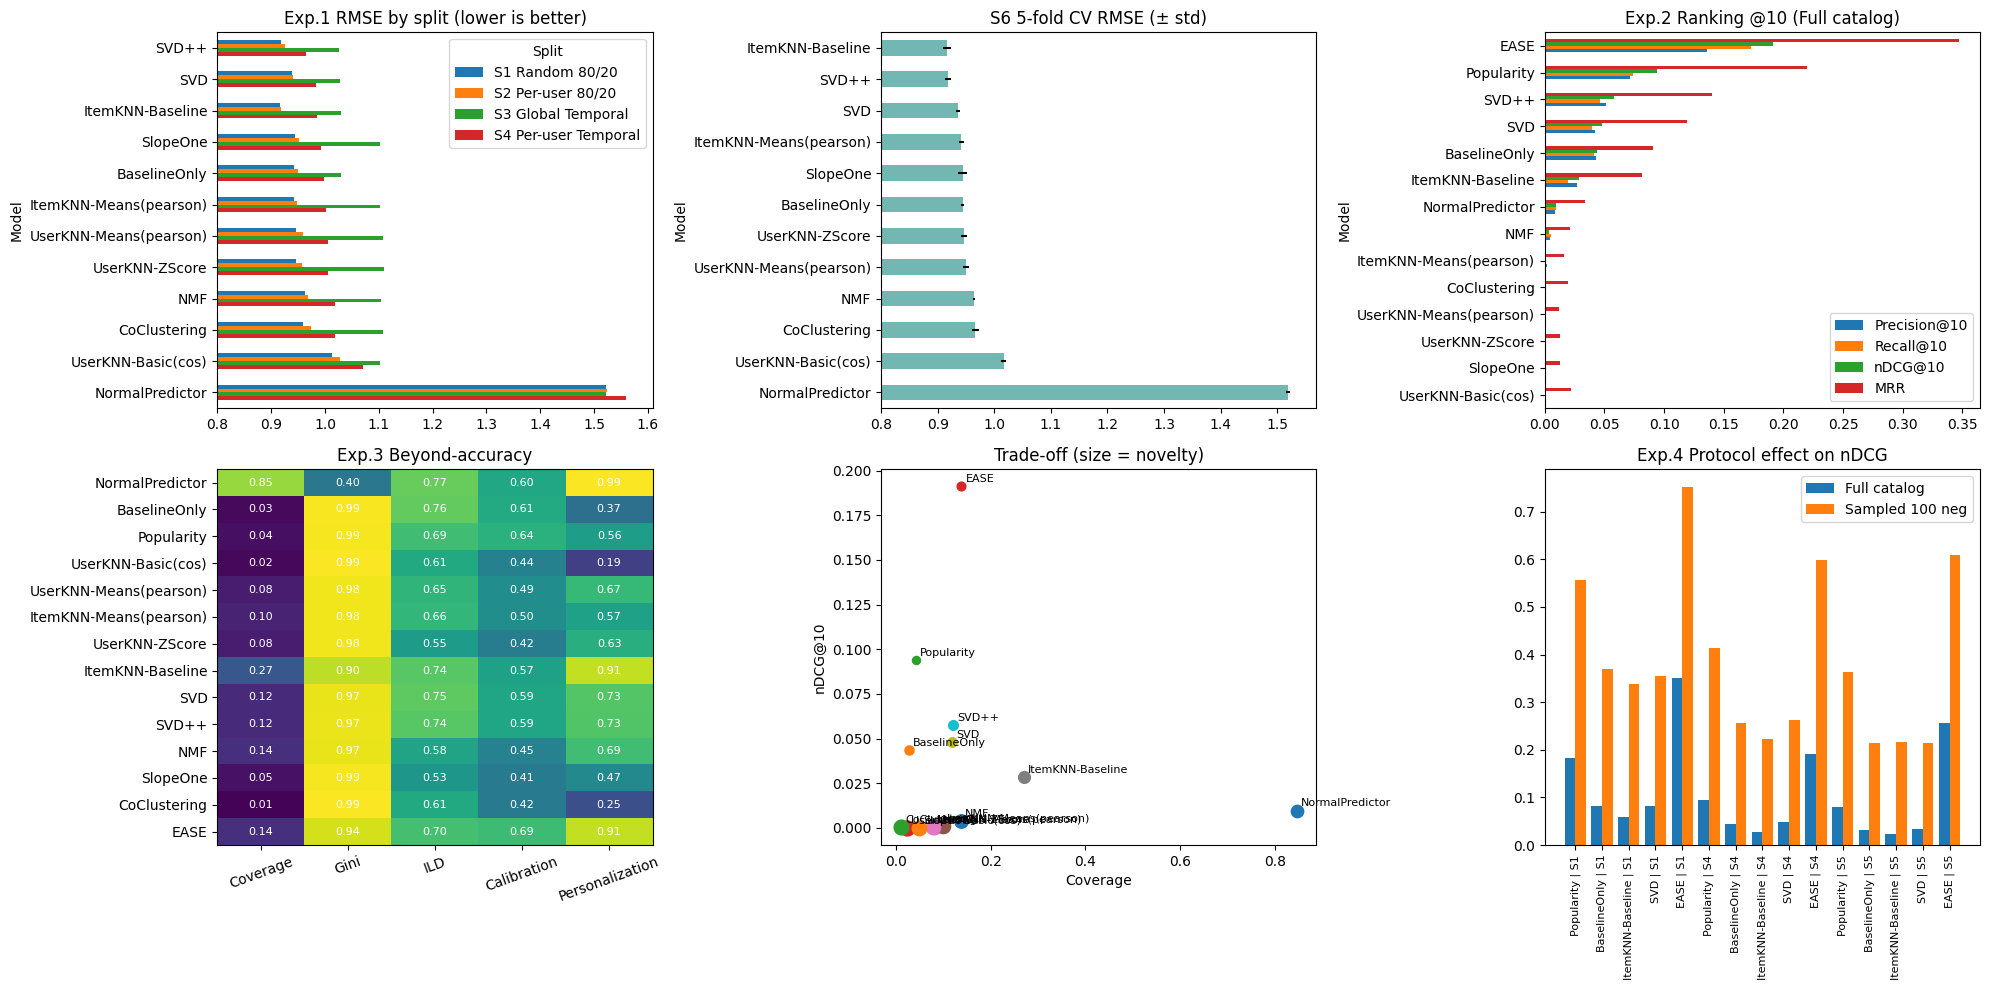

EASE − Popularity: Δ=0.0975  95% CI=[0.0751, 0.1192]  win/tie/loss=157/99/44 (ต่างอย่างมีหลักฐาน)
EASE − SVD++: Δ=0.1336  95% CI=[0.1116, 0.1560]  win/tie/loss=178/102/20 (ต่างอย่างมีหลักฐาน)
EASE − SVD: Δ=0.1432  95% CI=[0.1210, 0.1655]  win/tie/loss=172/101/27 (ต่างอย่างมีหลักฐาน)
EASE − ItemKNN-Baseline: Δ=0.1630  95% CI=[0.1408, 0.1847]  win/tie/loss=186/102/12 (ต่างอย่างมีหลักฐาน)


In [11]:
summary = ranking_results[["Model", "Family", f"HR@{K}", "MRR", f"nDCG@{K}", "AUC"] + BEYOND_COLS].merge(
    rating_results[rating_results.Split == MAIN_SPLIT][["Model", "RMSE", "MAE", "fit_s"]], on="Model", how="left")
display(summary.sort_values(f"nDCG@{K}", ascending=False).round(4).reset_index(drop=True))

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
piv = rating_results.pivot(index="Model", columns="Split", values="RMSE").sort_values(MAIN_SPLIT)
piv.plot.barh(ax=axes[0, 0]); axes[0, 0].set_xlim(0.8, piv.values[np.isfinite(piv.values)].max() + .05)
axes[0, 0].set_title("Exp.1 RMSE by split (lower is better)"); axes[0, 0].invert_yaxis()
cv_results.set_index("Model")["RMSE mean"].plot.barh(ax=axes[0, 1], xerr=cv_results.set_index("Model")["RMSE std"], color="#72B7B2")
axes[0, 1].set_xlim(0.8, cv_results["RMSE mean"].max() + .05); axes[0, 1].invert_yaxis(); axes[0, 1].set_title("S6 5-fold CV RMSE (± std)")
rk = ranking_results.set_index("Model")[[f"Precision@{K}", f"Recall@{K}", f"nDCG@{K}", "MRR"]].sort_values(f"nDCG@{K}")
rk.plot.barh(ax=axes[0, 2]); axes[0, 2].set_title(f"Exp.2 Ranking @{K} (Full catalog)")
bm = ranking_results.set_index("Model")[["Coverage", "Gini", "ILD", "Calibration", "Personalization"]]
im = axes[1, 0].imshow(bm.values, cmap="viridis", aspect="auto", vmin=0, vmax=1)
axes[1, 0].set_xticks(range(bm.shape[1])); axes[1, 0].set_xticklabels(bm.columns, rotation=20)
axes[1, 0].set_yticks(range(bm.shape[0])); axes[1, 0].set_yticklabels(bm.index)
for a in range(bm.shape[0]):
    for b in range(bm.shape[1]):
        axes[1, 0].text(b, a, f"{bm.values[a, b]:.2f}", ha="center", va="center", color="w", fontsize=8)
axes[1, 0].set_title("Exp.3 Beyond-accuracy")
for _, r in ranking_results.iterrows():
    axes[1, 1].scatter(r["Coverage"], r[f"nDCG@{K}"], s=20 + 10*r["Novelty"])
    axes[1, 1].annotate(r["Model"], (r["Coverage"], r[f"nDCG@{K}"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1, 1].set_xlabel("Coverage"); axes[1, 1].set_ylabel(f"nDCG@{K}"); axes[1, 1].set_title("Trade-off (size = novelty)")
pp = protocol_results.copy(); pp["label"] = pp.Model + " | " + pp.Split.str.split().str[0]
x = np.arange(len(pp)); axes[1, 2].bar(x - .2, pp[f"nDCG@{K}"], .4, label="Full catalog")
axes[1, 2].bar(x + .2, pp[f"nDCG@{K}(sampled)"], .4, label="Sampled 100 neg")
axes[1, 2].set_xticks(x); axes[1, 2].set_xticklabels(pp.label, rotation=90, fontsize=8); axes[1, 2].legend()
axes[1, 2].set_title("Exp.4 Protocol effect on nDCG")
plt.tight_layout(); plt.show()

# Paired bootstrap ระดับผู้ใช้ของ nDCG@K ระหว่างโมเดลอันดับ 1 กับโมเดลอื่น
def paired_bootstrap(a, b, metric=f"nDCG@{K}", B=2000, seed=SEED):
    da = RANK_DETAIL[a].set_index("user_id")[metric]; db = RANK_DETAIL[b].set_index("user_id")[metric]
    diff = (da - db.reindex(da.index)).dropna().values; rng = np.random.default_rng(seed)
    boots = rng.choice(diff, size=(B, len(diff)), replace=True).mean(1)
    return diff.mean(), np.percentile(boots, [2.5, 97.5]), (diff > 0).sum(), (diff == 0).sum(), (diff < 0).sum()
order = ranking_results.sort_values(f"nDCG@{K}", ascending=False).Model.tolist()
for other in list(dict.fromkeys(order[1:4] + ["SVD", "ItemKNN-Baseline"])):
    if other == order[0]: continue
    m_, ci, w, t, l = paired_bootstrap(order[0], other)
    print(f"{order[0]} − {other}: Δ={m_:.4f}  95% CI=[{ci[0]:.4f}, {ci[1]:.4f}]  win/tie/loss={w}/{t}/{l}",
          "(สรุปไม่ได้)" if ci[0] <= 0 <= ci[1] else "(ต่างอย่างมีหลักฐาน)")

## Part 11 — GUI: ข้อมูลผู้ใช้ + รายการแนะนำ + เทียบอัลกอริทึม + ทำนายคะแนน
- โหมด **Validation (S4)**: ใช้โมเดลที่ฝึกบนชุดฝึก แล้วทำเครื่องหมาย ✓ เมื่อแนะนำเรื่องที่ผู้ใช้ชอบจริงในอนาคต
- โหมด **Full data**: ฝึกบนข้อมูลทั้งหมด (เหมือนระบบจริงที่ให้บริการ)

In [12]:
import gradio as gr

ts_full = df_to_trainset(ratings)
FITTED_FULL = {}
def fitted_for(mode, name):
    if mode.startswith("Validation"): return FITTED[name], ts_main
    if name not in FITTED_FULL: FITTED_FULL[name] = get_model(name).fit(ts_full)
    return FITTED_FULL[name], ts_full

USER_CHOICES = sorted(ratings.user_id.unique(), key=int)
MOVIE_CHOICES = [f"{i} | {TITLE[i]}" for i in sorted(items.item_id, key=int)]

def user_profile(uid, ts_):
    info = users.set_index("user_id").loc[uid]
    u = ts_.to_inner_uid(uid); hist = [(ts_.to_raw_iid(j), r) for j, r in ts_.ur[u]]
    liked = [i for i, r in hist if r >= LIKE_T]
    g = pd.Series([x for i in liked for x in GENRE[i].split("|")]).value_counts().head(5)
    md = (f"### ผู้ใช้ {uid}\n- อายุ **{info.age}** · เพศ **{info.gender}** · อาชีพ **{info.occupation}** · zip {info.zip}\n"
          f"- จำนวนคะแนน (ในข้อมูลที่ใช้ฝึก): **{len(hist)}** · ค่าเฉลี่ย **{np.mean([r for _, r in hist]):.2f}** · ชอบ **{len(liked)}** เรื่อง\n"
          f"- แนวที่ชอบมากที่สุด: {', '.join(f'{k} ({v})' for k, v in g.items())}")
    h = pd.DataFrame([{"Movie": TITLE[i], "Genre": GENRE[i], "Rating": r} for i, r in hist])
    return md, h.sort_values("Rating", ascending=False).head(15)

def recommend(uid, name, k, mode):
    m, ts_ = fitted_for(mode, name); u = ts_.to_inner_uid(uid)
    seen = {j for j, _ in ts_.ur[u]}; sc = m.scores(u)
    order = [j for j in np.argsort(-sc, kind="stable") if j not in seen][:int(k)]
    rel = set(te_main[(te_main.user_id == uid) & (te_main.rating >= LIKE_T)].item_id) if mode.startswith("Validation") else set()
    pop = {ts_.to_raw_iid(i): len(v) for i, v in ts_.ir.items()}
    return pd.DataFrame([{"Rank": n, "Movie": TITLE[ts_.to_raw_iid(j)], "Year": YEAR.get(ts_.to_raw_iid(j)),
                          "Genre": GENRE[ts_.to_raw_iid(j)], "Score": round(float(sc[j]), 4),
                          "Pred. rating": round(m.predict(uid, ts_.to_raw_iid(j)), 2) if m.rating_model else "-",
                          "#ratings": pop.get(ts_.to_raw_iid(j), 0),
                          "Liked in validation": "✓" if ts_.to_raw_iid(j) in rel else ""} for n, j in enumerate(order, 1)])

def gui_main(uid, name, k, mode, compare_models):
    _, ts_ = fitted_for(mode, name)
    md, hist = user_profile(uid, ts_); rec = recommend(uid, name, k, mode)
    if mode.startswith("Validation"):
        fut = te_main[te_main.user_id == uid]
        md += f"\n- Validation (อนาคต): {len(fut)} คะแนน, ชอบ {int((fut.rating >= LIKE_T).sum())} เรื่อง → ✓ = แนะนำถูก"
    comp = pd.DataFrame({c: recommend(uid, c, k, mode).apply(lambda r: ("✓ " if r["Liked in validation"] else "") + r["Movie"], axis=1).values
                         for c in (compare_models or [])}, index=[f"#{n}" for n in range(1, int(k)+1)]).T.reset_index(names="Model")
    return md, hist, rec, comp

def gui_predict(uid, movie, mode):
    iid = movie.split(" | ")[0]
    true = ratings[(ratings.user_id == uid) & (ratings.item_id == iid)].rating
    rows = [{"Model": n, "Predicted rating": round(fitted_for(mode, n)[0].predict(uid, iid), 3)} for n in RATING_MODELS]
    return (f"จริง: {true.iloc[0] if len(true) else 'ยังไม่เคยให้คะแนน'}", pd.DataFrame(rows))

with gr.Blocks(title="Chapter 5 — CF on MovieLens-100K (Surprise)") as demo:
    gr.Markdown("## Chapter 5 — Collaborative Filtering on MovieLens-100K (Surprise)")
    with gr.Row():
        dd_u = gr.Dropdown(USER_CHOICES, value=SAMPLE_USERS[0], label="User")
        dd_m = gr.Dropdown(MODEL_NAMES, value="SVD", label="Algorithm")
        sl_k = gr.Slider(5, 20, 10, step=1, label="Top-K")
        rd = gr.Radio(["Validation (S4 temporal)", "Full data"], value="Validation (S4 temporal)", label="Mode")
    with gr.Tab("Recommend"):
        cg = gr.CheckboxGroup(MODEL_NAMES, value=["Popularity", "ItemKNN-Baseline", "SVD", "EASE"], label="เทียบกับอัลกอริทึม")
        bt = gr.Button("Recommend", variant="primary")
        md = gr.Markdown()
        with gr.Row():
            h = gr.Dataframe(label="User history (top-rated)")
            r = gr.Dataframe(label="Recommended movies")
        c = gr.Dataframe(label="Top-K comparison")
        bt.click(gui_main, [dd_u, dd_m, sl_k, rd, cg], [md, h, r, c])
    with gr.Tab("Predict rating"):
        dd_mv = gr.Dropdown(MOVIE_CHOICES, value=MOVIE_CHOICES[0], label="Movie")
        bp = gr.Button("Predict")
        out_t = gr.Markdown(); out_df = gr.Dataframe(label="Predicted rating by algorithm")
        bp.click(gui_predict, [dd_u, dd_mv, rd], [out_t, out_df])

demo.launch(debug=False)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b6f3df0dcfc4b585ba.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
